In [1]:
print("hello")

hello


In [1]:
import importlib
for lib in ["numpy", "pandas", "matplotlib", "sklearn", "torch"]:
    try:
        m = importlib.import_module(lib)
        print(lib, "✅", m.__version__)
    except ImportError:
        print(lib, "❌ MISSING")

numpy ✅ 2.4.6
pandas ✅ 3.0.3
matplotlib ✅ 3.11.0
sklearn ✅ 1.9.0
torch ❌ MISSING


In [2]:
import os, numpy as np, pandas as pd

print("labels file:", os.path.exists("labeled_anomalies.csv"))
print("train files:", len(os.listdir("data/train")))
print("test files:", len(os.listdir("data/test")))

x = np.load("data/train/A-1.npy")
print("A-1 shape:", x.shape)

labels file: True
train files: 82
test files: 82
A-1 shape: (2880, 25)


  chan_id spacecraft                           anomaly_sequences  \
0     P-1       SMAP  [[2149, 2349], [4536, 4844], [3539, 3779]]   
1     S-1       SMAP                              [[5300, 5747]]   
2     E-1       SMAP                [[5000, 5030], [5610, 6086]]   
3     E-2       SMAP                              [[5598, 6995]]   
4     E-3       SMAP                              [[5094, 8306]]   

                                  class  num_values  
0  [contextual, contextual, contextual]        8505  
1                               [point]        7331  
2              [contextual, contextual]        8516  
3                               [point]        8532  
4                               [point]        8307  
spacecraft
SMAP    55
MSL     27
Name: count, dtype: int64
anomaly ranges: [[4690, 4774]]


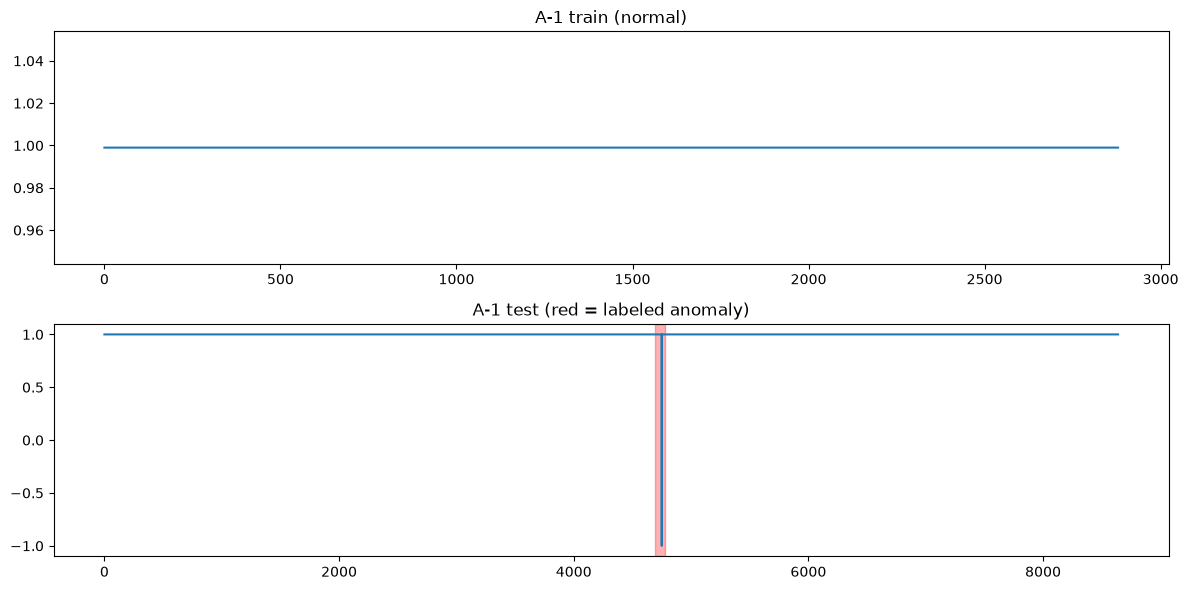

In [3]:
import ast
import matplotlib.pyplot as plt

labels = pd.read_csv("labeled_anomalies.csv")
print(labels.head())
print(labels["spacecraft"].value_counts())

ch = "A-1"
train = np.load(f"data/train/{ch}.npy")
test = np.load(f"data/test/{ch}.npy")
row = labels[labels["chan_id"] == ch].iloc[0]
anoms = ast.literal_eval(row["anomaly_sequences"])
print("anomaly ranges:", anoms)

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].plot(train[:, 0])
ax[0].set_title(f"{ch} train (normal)")
ax[1].plot(test[:, 0])
for s, e in anoms:
    ax[1].axvspan(s, e, color="red", alpha=0.3)
ax[1].set_title(f"{ch} test (red = labeled anomaly)")
plt.tight_layout()
plt.show()


flagged points: 1
caught inside true anomaly: 1 of 85
false alarms outside: 0


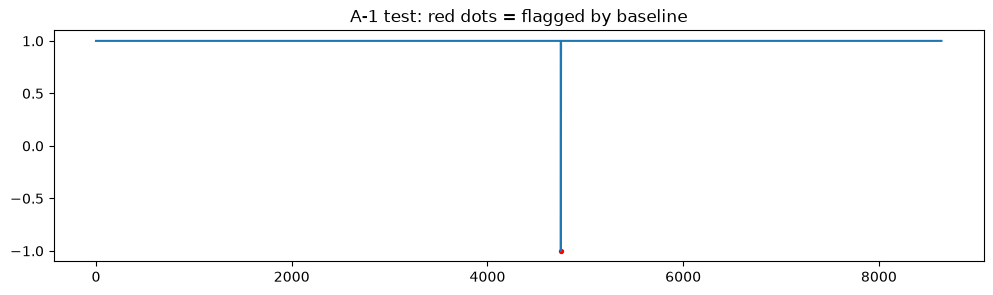

In [4]:
tr = train[:, 0]
te = test[:, 0]

def resid(a, w=50):
    med = pd.Series(a).rolling(w, center=True, min_periods=1).median().values
    return a - med

r_tr, r_te = resid(tr), resid(te)
thr = 5 * r_tr.std()
flags = np.abs(r_te) > thr

true = np.zeros(len(te), dtype=bool)
for s, e in anoms:
    true[s:e+1] = True

print("flagged points:", flags.sum())
print("caught inside true anomaly:", (flags & true).sum(), "of", true.sum())
print("false alarms outside:", (flags & ~true).sum())

plt.figure(figsize=(12, 3))
plt.plot(te)
plt.scatter(np.where(flags)[0], te[flags], color="red", s=8)
plt.title("A-1 test: red dots = flagged by baseline")
plt.show()

In [5]:
def segments(mask):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return []
    parts = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
    return [(p[0], p[-1]) for p in parts]

TP = FN = FP = 0
for _, row in labels.iterrows():
    ch = row["chan_id"]
    tr = np.load(f"data/train/{ch}.npy")[:, 0]
    te = np.load(f"data/test/{ch}.npy")[:, 0]
    ranges = ast.literal_eval(row["anomaly_sequences"])

    thr = max(5 * resid(tr).std(), 1e-6)
    flags = np.abs(resid(te)) > thr

    for s, e in ranges:
        if flags[s:e+1].any():
            TP += 1
        else:
            FN += 1
    for a, b in segments(flags):
        if not any(a <= e and b >= s for s, e in ranges):
            FP += 1

precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
print("TP:", TP, "FN:", FN, "FP:", FP)
print(f"precision {precision:.2f}  recall {recall:.2f}  F1 {f1:.2f}")

TP: 59 FN: 46 FP: 2270
precision 0.03  recall 0.56  F1 0.05


In [6]:
def merge(segs, gap):
    out = []
    for a, b in segs:
        if out and a - out[-1][1] <= gap:
            out[-1] = (out[-1][0], b)
        else:
            out.append((a, b))
    return out

def evaluate(k, gap=100):
    TP = FN = FP = 0
    for _, row in labels.iterrows():
        ch = row["chan_id"]
        tr = np.load(f"data/train/{ch}.npy")[:, 0]
        te = np.load(f"data/test/{ch}.npy")[:, 0]
        ranges = ast.literal_eval(row["anomaly_sequences"])
        thr = max(k * resid(tr).std(), 1e-6)
        segs = merge(segments(np.abs(resid(te)) > thr), gap)
        for s, e in ranges:
            if any(a <= e and b >= s for a, b in segs):
                TP += 1
            else:
                FN += 1
        for a, b in segs:
            if not any(a <= e and b >= s for s, e in ranges):
                FP += 1
    p = TP / (TP + FP) if TP + FP else 0
    r = TP / (TP + FN)
    f = 2 * p * r / (p + r) if p + r else 0
    return TP, FN, FP, p, r, f

for k in [5, 10, 20, 40]:
    TP, FN, FP, p, r, f = evaluate(k)
    print(f"k={k}: TP {TP} FN {FN} FP {FP} | P {p:.2f} R {r:.2f} F1 {f:.2f}")

k=5: TP 59 FN 46 FP 85 | P 0.41 R 0.56 F1 0.47
k=10: TP 49 FN 56 FP 37 | P 0.57 R 0.47 F1 0.51
k=20: TP 40 FN 65 FP 30 | P 0.57 R 0.38 F1 0.46
k=40: TP 36 FN 69 FP 30 | P 0.55 R 0.34 F1 0.42


In [7]:
from sklearn.ensemble import IsolationForest

def feats(a, w=50):
    s = pd.Series(a)
    return pd.DataFrame({
        "v": s,
        "mean": s.rolling(w, min_periods=1).mean(),
        "std": s.rolling(w, min_periods=1).std().fillna(0),
        "diff": s.diff().abs().fillna(0),
    }).values

cache = []
for _, row in labels.iterrows():
    ch = row["chan_id"]
    tr = np.load(f"data/train/{ch}.npy")[:, 0]
    te = np.load(f"data/test/{ch}.npy")[:, 0]
    m = IsolationForest(n_estimators=100, random_state=0).fit(feats(tr))
    cache.append((m.score_samples(feats(tr)), m.score_samples(feats(te)),
                  ast.literal_eval(row["anomaly_sequences"])))

def eval_if(q, gap=100):
    TP = FN = FP = 0
    for s_tr, s_te, ranges in cache:
        segs = merge(segments(s_te < np.quantile(s_tr, q)), gap)
        for s, e in ranges:
            if any(a <= e and b >= s for a, b in segs):
                TP += 1
            else:
                FN += 1
        for a, b in segs:
            if not any(a <= e and b >= s for s, e in ranges):
                FP += 1
    p = TP / (TP + FP) if TP + FP else 0
    r = TP / (TP + FN)
    f = 2 * p * r / (p + r) if p + r else 0
    return TP, FN, FP, p, r, f

for q in [0.001, 0.01, 0.02, 0.05]:
    TP, FN, FP, p, r, f = eval_if(q)
    print(f"q={q}: TP {TP} FN {FN} FP {FP} | P {p:.2f} R {r:.2f} F1 {f:.2f}")

q=0.001: TP 48 FN 57 FP 171 | P 0.22 R 0.46 F1 0.30
q=0.01: TP 74 FN 31 FP 526 | P 0.12 R 0.70 F1 0.21
q=0.02: TP 80 FN 25 FP 510 | P 0.14 R 0.76 F1 0.23
q=0.05: TP 84 FN 21 FP 258 | P 0.25 R 0.80 F1 0.38


In [8]:
for q in [0.1, 0.2, 0.3]:
    TP, FN, FP, p, r, f = eval_if(q)
    print(f"q={q}: TP {TP} FN {FN} FP {FP} | P {p:.2f} R {r:.2f} F1 {f:.2f}")

q=0.1: TP 85 FN 20 FP 128 | P 0.40 R 0.81 F1 0.53
q=0.2: TP 85 FN 20 FP 40 | P 0.68 R 0.81 F1 0.74
q=0.3: TP 85 FN 20 FP 31 | P 0.73 R 0.81 F1 0.77


In [9]:
for q in [0.05, 0.1, 0.2, 0.3]:
    fr = [(s_te < np.quantile(s_tr, q)).mean() for s_tr, s_te, _ in cache]
    print(f"q={q}: on average {100*np.mean(fr):.1f}% of test points flagged")

q=0.05: on average 21.3% of test points flagged
q=0.1: on average 31.5% of test points flagged
q=0.2: on average 44.7% of test points flagged
q=0.3: on average 51.9% of test points flagged


In [10]:
rng = np.random.default_rng(0)
if_scores = [(s_te, rg) for _, s_te, rg in cache]
rand_scores = [(rng.random(len(s)), rg) for s, rg in if_scores]

def eval_budget(scores_list, frac, gap=100):
    TP = FN = FP = 0
    for sc, ranges in scores_list:
        segs = merge(segments(sc <= np.quantile(sc, frac)), gap)
        for s, e in ranges:
            if any(a <= e and b >= s for a, b in segs):
                TP += 1
            else:
                FN += 1
        for a, b in segs:
            if not any(a <= e and b >= s for s, e in ranges):
                FP += 1
    p = TP / (TP + FP) if TP + FP else 0
    r = TP / (TP + FN)
    f = 2 * p * r / (p + r) if p + r else 0
    return TP, FN, FP, p, r, f

for frac in [0.01, 0.02, 0.05]:
    for name, sl in [("IsoForest", if_scores), ("Random", rand_scores)]:
        TP, FN, FP, p, r, f = eval_budget(sl, frac)
        print(f"{frac:.0%} {name:9s}: TP {TP} FP {FP} | P {p:.2f} R {r:.2f} F1 {f:.2f}")

1% IsoForest: TP 98 FP 626 | P 0.14 R 0.93 F1 0.24
1% Random   : TP 78 FP 1671 | P 0.04 R 0.74 F1 0.08
2% IsoForest: TP 101 FP 534 | P 0.16 R 0.96 F1 0.27
2% Random   : TP 97 FP 1183 | P 0.08 R 0.92 F1 0.14
5% IsoForest: TP 102 FP 377 | P 0.21 R 0.97 F1 0.35
5% Random   : TP 104 FP 135 | P 0.44 R 0.99 F1 0.60


In [11]:
W = 100
rng = np.random.default_rng(0)
data = []
for (_, row), (_, s_te, rg) in zip(labels.iterrows(), cache):
    ch = row["chan_id"]
    te = np.load(f"data/test/{ch}.npy")[:, 0]
    n = len(te) // W
    truth = np.zeros(n, dtype=bool)
    for s, e in rg:
        truth[s // W : min(e // W, n - 1) + 1] = True

    def wscore(sc):
        w = np.array([sc[i*W:(i+1)*W].min() for i in range(n)])
        return w + 1e-9 * rng.random(n)

    data.append((truth, wscore(-np.abs(resid(te))), wscore(s_te), rng.random(n)))

def eval_win(idx, frac):
    TP = FP = FN = 0
    for d in data:
        truth, sc = d[0], d[idx]
        flag = sc <= np.quantile(sc, frac)
        TP += (flag & truth).sum()
        FP += (flag & ~truth).sum()
        FN += (~flag & truth).sum()
    p = TP / (TP + FP)
    r = TP / (TP + FN)
    return p, r, (2 * p * r / (p + r) if p + r else 0)

allt = np.concatenate([d[0] for d in data])
print(f"truly anomalous windows: {100*allt.mean():.1f}% of all windows")
for frac in [0.02, 0.05, 0.10]:
    for name, idx in [("Baseline", 1), ("IsoForest", 2), ("Random", 3)]:
        p, r, f = eval_win(idx, frac)
        print(f"{frac:.0%} {name:9s}: P {p:.2f} R {r:.2f} F1 {f:.2f}")

truly anomalous windows: 14.2% of all windows
2% Baseline : P 0.65 R 0.12 F1 0.21
2% IsoForest: P 0.43 R 0.08 F1 0.14
2% Random   : P 0.11 R 0.02 F1 0.03
5% Baseline : P 0.48 R 0.20 F1 0.28
5% IsoForest: P 0.35 R 0.15 F1 0.21
5% Random   : P 0.11 R 0.05 F1 0.07
10% Baseline : P 0.37 R 0.28 F1 0.32
10% IsoForest: P 0.31 R 0.24 F1 0.27
10% Random   : P 0.10 R 0.08 F1 0.09


In [12]:
%pip install torch --index-url https://download.pytorch.org/whl/cpu

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://download.pytorch.org/whl/cpu
  Obtaining dependency information for torch from https://download-r2.pytorch.org/whl/cpu/torch-2.15.0%2Bcpu-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for filelock from https://files.pythonhosted.org/packages/e0/1b/5e74289a1878e666bb4b65fe5805a04cafcac2aa5f519ef1ead67ef91c56/filelock-4.2.4-py3-none-any.whl.metadata
  Obtaining dependency information for setuptools>=77.0.3 from https://download.pytorch.org/whl/setuptools-78.1.0-py3-none-any.whl.metadata
  Using cached https://download.pytorch.org/whl/setuptools-78.1.0-py3-none-any.whl.metadata (6.6 kB)
  Obtaining dependency information for sympy>=1.13.3 from https://files.pythonhosted.org/packages/a2/09/77d55d46fd61b4a135c444fc97158ef34a095e5681d0a6c10b75bf356191/sympy-1.14.0-py3-none-any.whl.metadata
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Obtaining d


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import torch
print(torch.__version__)

2.15.0+cpu


In [14]:
import torch, torch.nn as nn
torch.manual_seed(0)
L = 50

class Net(nn.Module):
    def __init__(self, f):
        super().__init__()
        self.lstm = nn.LSTM(f, 32, batch_first=True)
        self.out = nn.Linear(32, 1)
    def forward(self, x):
        o, _ = self.lstm(x)
        return self.out(o[:, -1]).squeeze(-1)

def make(a):
    X = np.stack([a[i:i+L] for i in range(len(a) - L)])
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(a[L:, 0], dtype=torch.float32))

lstm_err = []
for k, ch in enumerate(labels["chan_id"]):
    tr = np.load(f"data/train/{ch}.npy")
    te = np.load(f"data/test/{ch}.npy")
    Xtr, ytr = make(tr)
    Xte, yte = make(te)

    net = Net(tr.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=1e-2)
    for ep in range(5):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 128):
            idx = perm[i:i+128]
            opt.zero_grad()
            loss = nn.functional.mse_loss(net(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()

    with torch.no_grad():
        err = (net(Xte) - yte).abs().numpy()
    err = np.concatenate([np.zeros(L), err])
    err = pd.Series(err).rolling(10, min_periods=1).mean().values
    lstm_err.append(err)
    if (k + 1) % 20 == 0:
        print(f"{k + 1}/82 channels done")

# add LSTM scores to the same fair window-level test
rng2 = np.random.default_rng(1)
for i, d in enumerate(data):
    n = len(d[0])
    sc = -lstm_err[i]
    w = np.array([sc[j*W:(j+1)*W].min() for j in range(n)]) + 1e-9 * rng2.random(n)
    data[i] = d[:4] + (w,)

for frac in [0.02, 0.05, 0.10]:
    for name, idx in [("Baseline", 1), ("IsoForest", 2), ("LSTM", 4), ("Random", 3)]:
        p, r, f = eval_win(idx, frac)
        print(f"{frac:.0%} {name:9s}: P {p:.2f} R {r:.2f} F1 {f:.2f}")

20/82 channels done
40/82 channels done
60/82 channels done
80/82 channels done
2% Baseline : P 0.65 R 0.12 F1 0.21
2% IsoForest: P 0.43 R 0.08 F1 0.14
2% LSTM     : P 0.63 R 0.12 F1 0.20
2% Random   : P 0.11 R 0.02 F1 0.03
5% Baseline : P 0.48 R 0.20 F1 0.28
5% IsoForest: P 0.35 R 0.15 F1 0.21
5% LSTM     : P 0.47 R 0.20 F1 0.28
5% Random   : P 0.11 R 0.05 F1 0.07
10% Baseline : P 0.37 R 0.28 F1 0.32
10% IsoForest: P 0.31 R 0.24 F1 0.27
10% LSTM     : P 0.38 R 0.29 F1 0.33
10% Random   : P 0.10 R 0.08 F1 0.09


budget      10%    2%    5%
model                      
Baseline   0.32  0.21  0.28
IsoForest  0.27  0.14  0.21
LSTM       0.33  0.20  0.28
Random     0.09  0.03  0.07


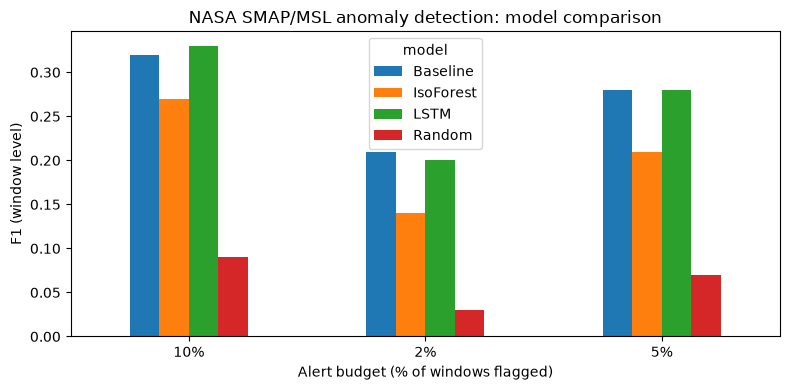

In [15]:
rows = []
for frac in [0.02, 0.05, 0.10]:
    for name, idx in [("Baseline", 1), ("IsoForest", 2), ("LSTM", 4), ("Random", 3)]:
        p, r, f = eval_win(idx, frac)
        rows.append({"budget": f"{frac:.0%}", "model": name,
                     "precision": round(p, 2), "recall": round(r, 2), "f1": round(f, 2)})

res = pd.DataFrame(rows)
res.to_csv("results.csv", index=False)
print(res.pivot(index="model", columns="budget", values="f1"))

pv = res.pivot(index="budget", columns="model", values="f1")[["Baseline", "IsoForest", "LSTM", "Random"]]
ax = pv.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("F1 (window level)")
ax.set_xlabel("Alert budget (% of windows flagged)")
ax.set_title("NASA SMAP/MSL anomaly detection: model comparison")
plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()

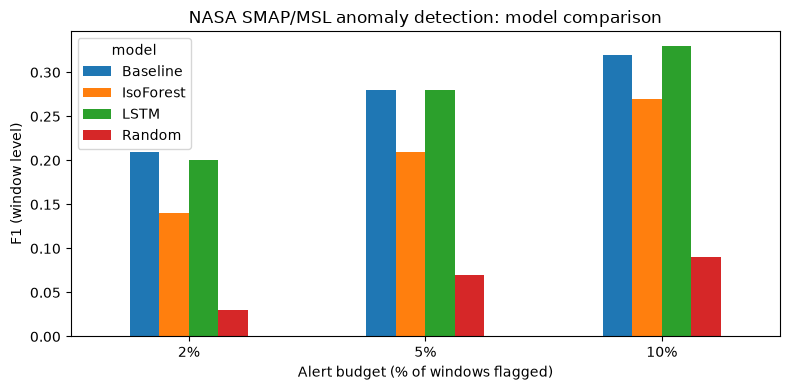

In [16]:
order = ["2%", "5%", "10%"]
pv = res.pivot(index="budget", columns="model", values="f1").loc[order, ["Baseline", "IsoForest", "LSTM", "Random"]]
ax = pv.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("F1 (window level)")
ax.set_xlabel("Alert budget (% of windows flagged)")
ax.set_title("NASA SMAP/MSL anomaly detection: model comparison")
plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()